Random Bond Ising Model:

We will be working on the random bond ising model on a 2D lattice, and we want to find the Nishimori curve, in which the probability that the probability of bonds being ferromagnetic is **exactly** related to the temperature of the system. Normally, in such a random system, which can be in a spin-glass phase, there is no correlation between this probability and the temperature. However, by requiring the disorder distribution to match the boltzmann distribution of the bonds, we extract the Nishimori condition that gives us an exact relationship. 

The Nishimori condition can be satisfied by the following:

Nishimori Condition

Setup. Consider the ±J random-bond Ising model with Hamiltonian

$$H = -\sum_{\langle ij \rangle} J_{ij}\, s_i s_j, \qquad s_i = \pm 1, \quad J_{ij} = \pm J$$

with bond distribution

$$P(J_{ij} = +J) = p, \qquad P(J_{ij} = -J) = 1 - p.$$

Condition. The Nishimori line is the set of $(p, T)$ where the bond distribution matches the Boltzmann weight of the couplings:

$$P(J_{ij}) \propto e^{\beta J_{ij}}, \qquad \beta = \frac{1}{k_B T}$$

Normalizing gives $P(+J) = \dfrac{e^{\beta J}}{2\cosh \beta J}$. Taking the ratio of the two bond probabilities yields the exact relationship:

$$\boxed{\frac{p}{1-p} = e^{2\beta J}}$$

Equivalent forms.

$$p = \frac{e^{2\beta J}}{1 + e^{2\beta J}}, \qquad \tanh(\beta J) = 2p - 1$$

Interpretation.

Each temperature $T$ corresponds to exactly one bond probability $p(T)$ on the line.
As $T \to 0$, $p \to 1$ (pure ferromagnet). As $T \to \infty$, $p \to 1/2$ (fully random signs).
Off the line, $p$ and $T$ are independent parameters.

Overall Setup of The Problem:

Lattice: a 2D square lattice of N = L×L sites with periodic boundary conditions. 

Disorder: assign each bond Jᵢⱼ = +J with probability p and −J with probability 1 − p. Draw these once per realization.

Hamiltonian: H = −Σ⟨ij⟩ Jᵢⱼ sᵢsⱼ, with sᵢ = ±1.

Temperature sweep: for fixed couplings, run Monte Carlo at a range of T to sample spin configurations from the Boltzmann distribution at each 
temperature. 

Averaging: measure observables (energy, magnetization, overlap, correlations) for each sample, then average over many disorder realizations.

Parameter choice: fix p, or pick p(T) on the Nishimori line to get the exact identities as a check.

## Implementation

Conventions: $J = 1$, $k_B = 1$ (so $\beta = 1/T$). Bonds live on two arrays: `Jx[r,i,j]` links $(i,j)\to(i,j+1)$ and `Jy[r,i,j]` links $(i,j)\to(i+1,j)$, with indices wrapping around (periodic boundaries). The leading index `r` labels independent disorder realizations, which are simulated side by side so that one numpy call updates all of them.

In [1]:
import numpy as np

# Conventions: J = 1, k_B = 1, so beta = 1/T.  Lattice is L x L, periodic, L even.
# Arrays have shape (n_real, L, L): n_real independent disorder realizations simulated side by side.
J = 1.0

In [2]:
class RandomBondIsingModel:
    """n_real independent disorder realizations of the +-J random-bond Ising model on an L x L torus."""

    def __init__(self, L, p, n_real, rng):
        assert L % 2 == 0, "checkerboard updates need even L"
        self.L, self.p, self.n_real, self.rng = L, p, n_real, rng
        self.Jx, self.Jy = self.draw_bonds()
        self.spins = self.random_spins()

    def draw_bonds(self):
        # Jx[r, i, j] couples site (i, j) to its right neighbour (i, j+1);
        # Jy[r, i, j] couples site (i, j) to the neighbour below (i+1, j).
        # Each bond is +J with probability p and -J with probability 1 - p.
        # Indices wrap around (np.roll below), giving periodic boundary conditions.
        shape = (self.n_real, self.L, self.L)
        Jx = np.where(self.rng.random(shape) < self.p, J, -J)
        Jy = np.where(self.rng.random(shape) < self.p, J, -J)
        return Jx, Jy

    def random_spins(self):
        return self.rng.choice([-1, 1], size=(self.n_real, self.L, self.L))

    def local_field(self, s):
        # h_i = sum over the 4 neighbours j of J_ij s_j  (each bond used from both ends)
        return (self.Jx * np.roll(s, -1, axis=2) + np.roll(self.Jx * s, 1, axis=2)
                + self.Jy * np.roll(s, -1, axis=1) + np.roll(self.Jy * s, 1, axis=1))

    def energy(self, s):
        # H = -sum_<ij> J_ij s_i s_j ; each bond counted once (right + down). One value per realization.
        return -np.sum(self.Jx * s * np.roll(s, -1, axis=2) + self.Jy * s * np.roll(s, -1, axis=1), axis=(1, 2))

    def magnetization(self, s):
        return np.mean(s, axis=(1, 2))

### Monte Carlo temperature sweep

Checkerboard Metropolis: sites of one colour have no bonds between them, so all of them can be updated at once. Flipping $s_i$ changes the energy by $\Delta E = 2 s_i h_i$, where $h_i = \sum_j J_{ij} s_j$.

In [3]:
def metropolis_sweep(model, s, beta):
    """One Monte Carlo sweep = update all black sites, then all white sites.
    Sites of one colour share no bonds, so they can be flipped simultaneously."""
    i, j = np.indices((model.L, model.L))
    for colour in (0, 1):
        mask = (i + j) % 2 == colour
        dE = 2 * s * model.local_field(s)           # energy change if s_i -> -s_i
        accept = model.rng.random(s.shape) < np.exp(-beta * dE)
        s = np.where(mask & accept, -s, s)
    return s


def temperature_sweep(model, temperatures, n_equil, n_measure):
    """For fixed bonds, run Metropolis at each T (in the order given, reusing the last
    configuration as a warm start). Returns E and m with shape (n_T, n_measure, n_real)."""
    E_samples, m_samples = [], []
    s = model.spins
    for T in temperatures:
        beta = 1.0 / T
        for _ in range(n_equil):
            s = metropolis_sweep(model, s, beta)
        E, m = [], []
        for _ in range(n_measure):
            s = metropolis_sweep(model, s, beta)
            E.append(model.energy(s))
            m.append(model.magnetization(s))
        E_samples.append(E)
        m_samples.append(m)
    model.spins = s
    return np.array(E_samples), np.array(m_samples)

In [4]:
def nishimori_p(T):
    # p / (1 - p) = exp(2 beta J)  <=>  p = 1 / (1 + exp(-2 J / T))
    return 1.0 / (1.0 + np.exp(-2.0 * J / T))

## Consistency checks

In [5]:
# Check 1: the local field must reproduce brute-force energy differences,
# E(s with s_i flipped) - E(s) = 2 s_i h_i, at every site (this tests the bond/roll bookkeeping).
rng = np.random.default_rng(0)
model = RandomBondIsingModel(L=6, p=0.7, n_real=3, rng=rng)
s = model.spins
h = model.local_field(s)
for a in range(model.L):
    for b in range(model.L):
        s_flip = s.copy()
        s_flip[:, a, b] *= -1
        assert np.all(model.energy(s_flip) - model.energy(s) == 2 * s[:, a, b] * h[:, a, b])
print("local field matches brute-force energy differences at all", model.L**2, "sites, in every realization")

local field matches brute-force energy differences at all 36 sites, in every realization


In [6]:
# Check 2 (Nishimori identity): on the Nishimori line the disorder-averaged energy is exact,
#   [<E>] / N_bonds = -J tanh(beta J),   with N_bonds = 2 L^2 on the periodic square lattice.
L, n_real = 16, 20
for T in [0.8, 1.5, 3.0]:
    p = nishimori_p(T)
    model = RandomBondIsingModel(L, p, n_real, rng)
    E, m = temperature_sweep(model, [T], n_equil=500, n_measure=500)
    E_real = E[0].mean(axis=0)                     # thermal average, one value per realization
    e_mc = E_real.mean() / (2 * L**2)
    err = E_real.std() / np.sqrt(n_real) / (2 * L**2)
    print(f"T={T:.2f}  p={p:.4f}  MC: {e_mc:.4f} +- {err:.4f}   exact: {-np.tanh(J / T):.4f}")

T=0.80  p=0.9241  MC: -0.8428 +- 0.0066   exact: -0.8483
T=1.50  p=0.7914  MC: -0.5819 +- 0.0039   exact: -0.5828


T=3.00  p=0.6608  MC: -0.3211 +- 0.0011   exact: -0.3215


## Step 2: Phase diagram and the Nishimori point

The Nishimori line is known exactly, but the ferro/para phase boundary is not, so we measure it.
The Nishimori line crosses the boundary at the **Nishimori point**, a multicritical point
(literature: $p_N \approx 0.8907$, $T_N \approx 0.953$).

**Binder cumulant.** $g = \tfrac12\left(3 - [\langle m^4\rangle]/[\langle m^2\rangle]^2\right)$, where $\langle\cdot\rangle$ is the thermal average and $[\cdot]$ the disorder average.
$g \to 1$ in the ferromagnet and $g \to 0$ in the paramagnet, and at $T_c$ it is independent of $L$. So the $g(T)$ curves for different $L$ **cross at $T_c$**.
We locate crossings along fixed-$p$ cuts and along the Nishimori line itself, using $L = 8, 12, 16$.
(Larger $L$ do not equilibrate with single-spin Metropolis in reasonable time.)

**Starting state.** Each run starts from all spins up. On the Nishimori line this is gauge-equivalent to the
"planted" configuration, which is an exact equilibrium sample ("quiet planting"), so we start already in equilibrium.
The burn-in only has to wash out the correlation with the starting state. Check 3 tests that the burn-in is long enough.

**Error bars.** These come from bootstrap resampling of the disorder realizations.

In [7]:
def binder_data(L, p_of_T, temperatures, n_real, n_equil, n_measure, rng):
    """At each T draw fresh bonds with p = p_of_T(T) and run Metropolis from the all-up state.
    Returns per-realization thermal moments <m^2>, <m^4>, each of shape (n_T, n_real)."""
    m2, m4 = [], []
    for T in temperatures:
        model = RandomBondIsingModel(L, p_of_T(T), n_real, rng)
        model.spins = np.ones_like(model.spins)          # all-up start (quiet planting on the Nishimori line)
        _, m = temperature_sweep(model, [T], n_equil, n_measure)
        m2.append(np.mean(m[0]**2, axis=0))
        m4.append(np.mean(m[0]**4, axis=0))
    return np.array(m2), np.array(m4)


def binder(m2, m4):
    # disorder average (last axis) taken separately in numerator and denominator
    return 0.5 * (3 - m4.mean(axis=-1) / m2.mean(axis=-1)**2)


def crossing(Ts, g_small, g_large):
    """T where g_small - g_large changes sign from - (ferro: larger L more ordered) to +,
    by linear interpolation between the bracketing grid points."""
    d = g_small - g_large
    k = np.flatnonzero((d[:-1] < 0) & (d[1:] >= 0))
    assert len(k) > 0, "Binder curves do not cross on this temperature grid"
    k = k[0]
    return Ts[k] - d[k] * (Ts[k + 1] - Ts[k]) / (d[k + 1] - d[k])


def crossing_with_error(Ts, data_small, data_large, rng, n_boot=200):
    """Crossing temperature and its bootstrap error (resampling disorder realizations)."""
    n_real = data_small[0].shape[1]
    boots = []
    for _ in range(n_boot):
        r = rng.integers(0, n_real, n_real)
        boots.append(crossing(Ts, binder(data_small[0][:, r], data_small[1][:, r]),
                                  binder(data_large[0][:, r], data_large[1][:, r])))
    return crossing(Ts, binder(*data_small), binder(*data_large)), np.std(boots)

In [8]:
# Check 3 (equilibration): at the Nishimori point, the largest size, g must not change
# when the burn-in is quadrupled. (Starting all-up biases g upward if the burn-in is too short.)
T = 0.95
for n_equil in (1000, 4000):
    m2, m4 = binder_data(16, nishimori_p, [T], n_real=200, n_equil=n_equil, n_measure=1000, rng=rng)
    g = binder(m2, m4)[0]
    g_boot = [binder(m2[:, r], m4[:, r])[0] for r in rng.integers(0, 200, (200, 200))]
    print(f"L=16, T={T}, n_equil={n_equil}:  g = {g:.3f} +- {np.std(g_boot):.3f}")

L=16, T=0.95, n_equil=1000:  g = 0.958 +- 0.006


L=16, T=0.95, n_equil=4000:  g = 0.952 +- 0.006


In [9]:
import multiprocessing as mp

# Binder curves for L = 8, 12, 16 along fixed-p cuts and along the Nishimori line.
# Each temperature grid brackets the crossing found in a coarse scan. Takes ~1-2 min on 5 cores.
Ls = (8, 12, 16)
n_real, n_equil, n_measure = 200, 1000, 1000
cuts = {                                      # label: (p as a function of T, temperature grid)
    "p = 1":          (lambda T: 1.0,  np.linspace(2.15, 2.40, 11)),
    "p = 0.96":       (lambda T: 0.96, np.linspace(1.80, 2.10, 11)),
    "p = 0.93":       (lambda T: 0.93, np.linspace(1.50, 1.85, 11)),
    "p = 0.91":       (lambda T: 0.91, np.linspace(1.20, 1.60, 11)),
    "Nishimori line": (nishimori_p,    np.linspace(0.85, 1.10, 11)),
}


def run_cut(label, seed):
    """All L for one cut. Each cut gets its own independent random stream (seed), since forked
    workers would otherwise inherit identical copies of the global rng."""
    p_of_T, Ts = cuts[label]
    cut_rng = np.random.default_rng(seed)
    return {L: binder_data(L, p_of_T, Ts, n_real, n_equil, n_measure, cut_rng) for L in Ls}


# The five cuts are independent, so run them in parallel, one process each.
# "fork" lets workers see functions defined in this notebook (macOS defaults to "spawn", which cannot).
seeds = np.random.SeedSequence(2026).spawn(len(cuts))
with mp.get_context("fork").Pool(len(cuts)) as pool:
    results = pool.starmap(run_cut, zip(cuts, seeds))
data = dict(zip(cuts, results))

# Crossing of the two largest sizes (smallest finite-size corrections); (8, 16) printed for comparison.
Tc = {}
for label, (p_of_T, Ts) in cuts.items():
    Tc[label] = crossing_with_error(Ts, data[label][12], data[label][16], rng)
    T816 = crossing(Ts, binder(*data[label][8]), binder(*data[label][16]))
    print(f"{label:15s}  T_c(12,16) = {Tc[label][0]:.3f} +- {Tc[label][1]:.3f}    T_c(8,16) = {T816:.3f}")

p = 1            T_c(12,16) = 2.278 +- 0.007    T_c(8,16) = 2.268
p = 0.96         T_c(12,16) = 1.956 +- 0.030    T_c(8,16) = 1.944
p = 0.93         T_c(12,16) = 1.694 +- 0.056    T_c(8,16) = 1.696
p = 0.91         T_c(12,16) = 1.388 +- 0.070    T_c(8,16) = 1.410
Nishimori line   T_c(12,16) = 0.968 +- 0.059    T_c(8,16) = 0.987


In [10]:
# Check 4 (pure Ising limit): at p = 1 the crossing must reproduce Onsager's exact T_c.
T_onsager = 2 / np.log(1 + np.sqrt(2))
print(f"p = 1:  T_c = {Tc['p = 1'][0]:.3f} +- {Tc['p = 1'][1]:.3f}    Onsager: {T_onsager:.4f}")

# Nishimori point: the crossing along the line gives T_N, and p_N = nishimori_p(T_N).
T_N, dT_N = Tc["Nishimori line"]
p_N = nishimori_p(T_N)
dp_N = abs(nishimori_p(T_N + dT_N) - nishimori_p(T_N - dT_N)) / 2
print(f"Nishimori point:  p_N = {p_N:.4f} +- {dp_N:.4f},  T_N = {T_N:.3f} +- {dT_N:.3f}"
      f"    literature: p_N = 0.8907, T_N = 0.953")

p = 1:  T_c = 2.278 +- 0.007    Onsager: 2.2692
Nishimori point:  p_N = 0.8875 +- 0.0125,  T_N = 0.968 +- 0.059    literature: p_N = 0.8907, T_N = 0.953


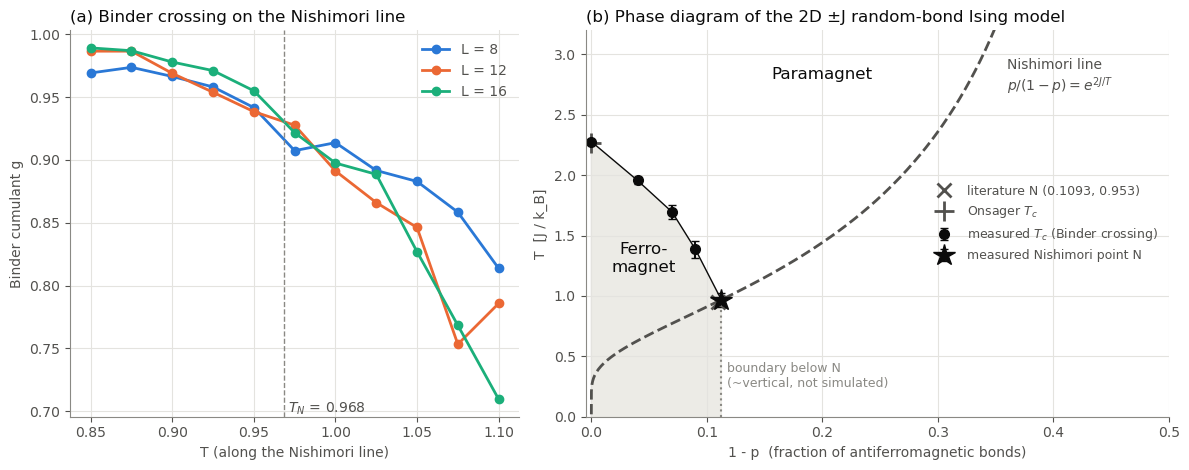

In [11]:
import matplotlib.pyplot as plt

INK, INK2, MUTED, GRID, SHADE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#ecebe6"
L_COLOURS = {8: "#2a78d6", 12: "#eb6834", 16: "#1baf7a"}
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False})

fig, (ax_g, ax_pd) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

# (a) Binder curves along the Nishimori line: their crossing locates T_N.
Ts = cuts["Nishimori line"][1]
for L in Ls:
    ax_g.plot(Ts, binder(*data["Nishimori line"][L]), "-o", color=L_COLOURS[L], lw=2, ms=6, label=f"L = {L}")
ax_g.axvline(T_N, color=MUTED, lw=1, ls="--")
ax_g.text(T_N, ax_g.get_ylim()[0], f" $T_N$ = {T_N:.3f}", color=INK2, va="bottom")
ax_g.set(xlabel="T (along the Nishimori line)", ylabel="Binder cumulant g")
ax_g.set_title("(a) Binder crossing on the Nishimori line", color=INK, loc="left")
ax_g.legend(frameon=False, labelcolor=INK2)
ax_g.grid(color=GRID, lw=0.8)

# (b) Phase diagram, plotted against the antiferromagnetic bond fraction q = 1 - p
#     (the convention of most papers: q = 0 is the pure ferromagnet, q = 1/2 fully random).
T_line = np.linspace(0.02, 5.0, 400)
q_line = 1 - nishimori_p(T_line)                        # exact: p/(1-p) = exp(2 J / T)
ax_pd.plot(q_line, T_line, color=INK2, lw=2, ls="--")
ax_pd.text(0.36, 2.7, "Nishimori line\n$p/(1-p) = e^{2J/T}$", color=INK2)

fixed_p = {"p = 1": 1.0, "p = 0.96": 0.96, "p = 0.93": 0.93, "p = 0.91": 0.91}
q_pts = 1 - np.array([fixed_p[k] for k in fixed_p] + [p_N])
T_pts = np.array([Tc[k][0] for k in fixed_p] + [T_N])
dT_pts = np.array([Tc[k][1] for k in fixed_p] + [dT_N])
q_N = 1 - p_N
order = np.argsort(q_pts)
ax_pd.plot(q_pts[order], T_pts[order], color=INK, lw=1)                  # guide to the eye
# Ferromagnetic region: under the measured T_c, left of the (assumed vertical) boundary below N.
ax_pd.fill(np.r_[0, q_pts[order], q_N, 0], np.r_[0, T_pts[order], 0, 0], color=SHADE, zorder=0)
ax_pd.errorbar(q_pts[:-1], T_pts[:-1], yerr=dT_pts[:-1], fmt="o", color=INK, ms=7, capsize=3,
               label="measured $T_c$ (Binder crossing)")
ax_pd.errorbar([q_N], [T_N], yerr=[dT_N], fmt="*", color=INK, ms=16, capsize=3, label="measured Nishimori point N")
ax_pd.plot([1 - 0.8907], [0.953], "x", color=INK2, ms=10, mew=2, label="literature N (0.1093, 0.953)")
ax_pd.plot([0.0], [T_onsager], "+", color=INK2, ms=14, mew=2, label="Onsager $T_c$")
ax_pd.plot([q_N, q_N], [0, T_N], color=MUTED, lw=1.5, ls=":")           # below N: boundary ~vertical, not simulated
ax_pd.text(q_N + 0.005, 0.25, "boundary below N\n(~vertical, not simulated)", color=MUTED, fontsize=9)

ax_pd.text(0.045, 1.2, "Ferro-\nmagnet", color=INK, ha="center", fontsize=12)
ax_pd.text(0.20, 2.8, "Paramagnet", color=INK, ha="center", fontsize=12)
ax_pd.set(xlim=(-0.005, 0.5), ylim=(0, 3.2), xlabel="1 - p  (fraction of antiferromagnetic bonds)",
          ylabel="T  [J / k_B]")
ax_pd.set_title("(b) Phase diagram of the 2D ±J random-bond Ising model", color=INK, loc="left")
ax_pd.legend(frameon=False, loc="center right", labelcolor=INK2, fontsize=9)
ax_pd.grid(color=GRID, lw=0.8)

fig.tight_layout()
fig.savefig("nishimori_phase_diagram.png", dpi=150)
plt.show()

## Results and interpretation

### (a) Why the Binder crossing locates the transition

The Binder cumulant $g = \tfrac12\left(3 - [\langle m^4\rangle]/[\langle m^2\rangle]^2\right)$ is a ratio of moments. Overall factors of the magnetization cancel, so $g$ depends only on the *shape* of the distribution $P(m)$:

- **Ferromagnet** ($T < T_c$): $P(m)$ has two sharp peaks at $\pm m_0$, so $\langle m^4\rangle \to \langle m^2\rangle^2$ and $g \to 1$. Larger $L$ makes the peaks sharper, pushing $g$ closer to 1.
- **Paramagnet** ($T > T_c$): $P(m)$ is a Gaussian centred at 0, so $\langle m^4\rangle = 3\langle m^2\rangle^2$ and $g \to 0$. Larger $L$ makes it more Gaussian, pushing $g$ closer to 0.
- **Critical point** ($T = T_c$): the correlation length diverges, so the lattice size $L$ is the only length left. The system is scale invariant: $P(m)$ has the same shape at every $L$, so $g$ takes the same universal value $g^*$ for all $L$.

Finite-size scaling makes this precise: $g = \tilde g\big((T - T_c)\,L^{1/\nu}\big)$. At $T = T_c$ the argument is zero for every $L$, so all the curves pass through one point. The curves for larger $L$ are steeper ($L^{1/\nu}$), so the order of the curves flips at the crossing.

This gives $T_c$ **without knowing any critical exponent**, and the leading finite-size shift cancels. That is why it works with $L \le 16$.
In panel (a), larger $L$ has larger $g$ below the crossing and smaller $g$ above it, as expected. The crossing gives $T_N = 0.968 \pm 0.059$.
The curves cross at a shallow angle with noise of order 0.01, which is why the error bar on $T_N$ is the largest in the study.

**Check:** at $p = 1$ the same method gives $T_c = 2.278 \pm 0.007$, against Onsager's exact $2/\ln(1+\sqrt2) = 2.2692$.
The small offset reflects corrections to scaling at $L \le 16$ and the interpolation between grid points. The bootstrap error bar captures neither, so the true uncertainty is closer to $\pm 0.02$.

### (b) What the phase diagram shows

- **Phase boundary $T_c(p)$.** Adding antiferromagnetic bonds introduces *frustration*. Some plaquettes cannot satisfy all four bonds, and that weakens long-range order. $T_c$ falls from the Onsager value at $1-p = 0$ to the Nishimori point.
- **Nishimori line.** This is the exact curve $p/(1-p) = e^{2J/T}$, where the disorder distribution matches the Boltzmann weight of the bonds. Along it, a gauge symmetry makes some quantities exactly computable. One example is the energy $[\langle E\rangle] = -N_B J\tanh\beta J$, which is Check 2. Another is the identity $[\langle m\rangle] = [\langle q\rangle]$.
  The line starts at the origin inside the ferromagnet and climbs through the paramagnet to $1-p = \tfrac12$ as $T \to \infty$. So it cuts **across** the phase boundary, and it does so at exactly one point.
- **Nishimori point N.** This is where the line crosses the boundary. It is a **multicritical point**: it belongs to a different universality class from the pure Ising transition, because both disorder and temperature are relevant there.
  Our estimate is $(1-p_N, T_N) = (0.1125 \pm 0.0125,\ 0.968 \pm 0.059)$, against the literature value $(0.1093,\ 0.953)$, so they agree within $1\sigma$.
- **The boundary below N.** Nishimori's gauge argument gives the bound $\big|[\langle s_i s_j\rangle]_T\big| \le [\,|\langle s_i s_j\rangle_{T_N(p)}|\,]$. In words: at fixed $p$, correlations are strongest on the Nishimori line.
  So if the system is disordered at the Nishimori temperature for that $p$, it is disordered at *every* temperature. Ferromagnetic order therefore cannot extend past N in $1-p$, and the boundary below N must be vertical (or bend back, "reentrant").
  We drew it vertical but did not simulate it: at low $T$, Metropolis cannot equilibrate the frustrated system.
- **Paramagnet at low T.** In 2D the spin-glass phase exists only at $T = 0$, so the low-$T$ region at $1-p > 1-p_N$ is paramagnetic. In 3D, or in mean-field (SK) models, this corner is a spin-glass phase instead.

*The numbers above come from the run with seed `SeedSequence(2026)`. They change slightly if the seed or the run parameters are changed.*